In [7]:
from pathlib import Path

# Chemin du dossier principal et extensions d'images prises en charge.
dataset_dir = Path("dataset")
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Parcourir les trois parties du jeu de données.
for split in ("test", "train", "valid"):
    images_dir = dataset_dir / split / "images"
    labels_dir = dataset_dir / split / "labels"

    # Récupérer les noms des images et des fichiers d'annotation.
    images = {
        image.stem
        for image in images_dir.iterdir()
        if image.is_file() and image.suffix.lower() in image_extensions
    }
    labels = {
        label.stem
        for label in labels_dir.glob("*.txt")
        if label.is_file()
    }

    # Comparer les noms pour repérer les fichiers sans paire correspondante.
    images_sans_label = images - labels
    labels_sans_image = labels - images

    # Afficher les totaux et les éventuelles correspondances manquantes.
    print(f"\n{split.upper()}")
    print(f"Images : {len(images)}")
    print(f"Fichiers texte : {len(labels)}")
    print(f"Images sans fichier texte correspondant : {len(images_sans_label)}")
    print(f"Fichiers texte sans image correspondante : {len(labels_sans_image)}")


TEST
Images : 532
Fichiers texte : 532
Images sans fichier texte correspondant : 0
Fichiers texte sans image correspondante : 0

TRAIN
Images : 3710
Fichiers texte : 3710
Images sans fichier texte correspondant : 0
Fichiers texte sans image correspondante : 0

VALID
Images : 1059
Fichiers texte : 1059
Images sans fichier texte correspondant : 0
Fichiers texte sans image correspondante : 0


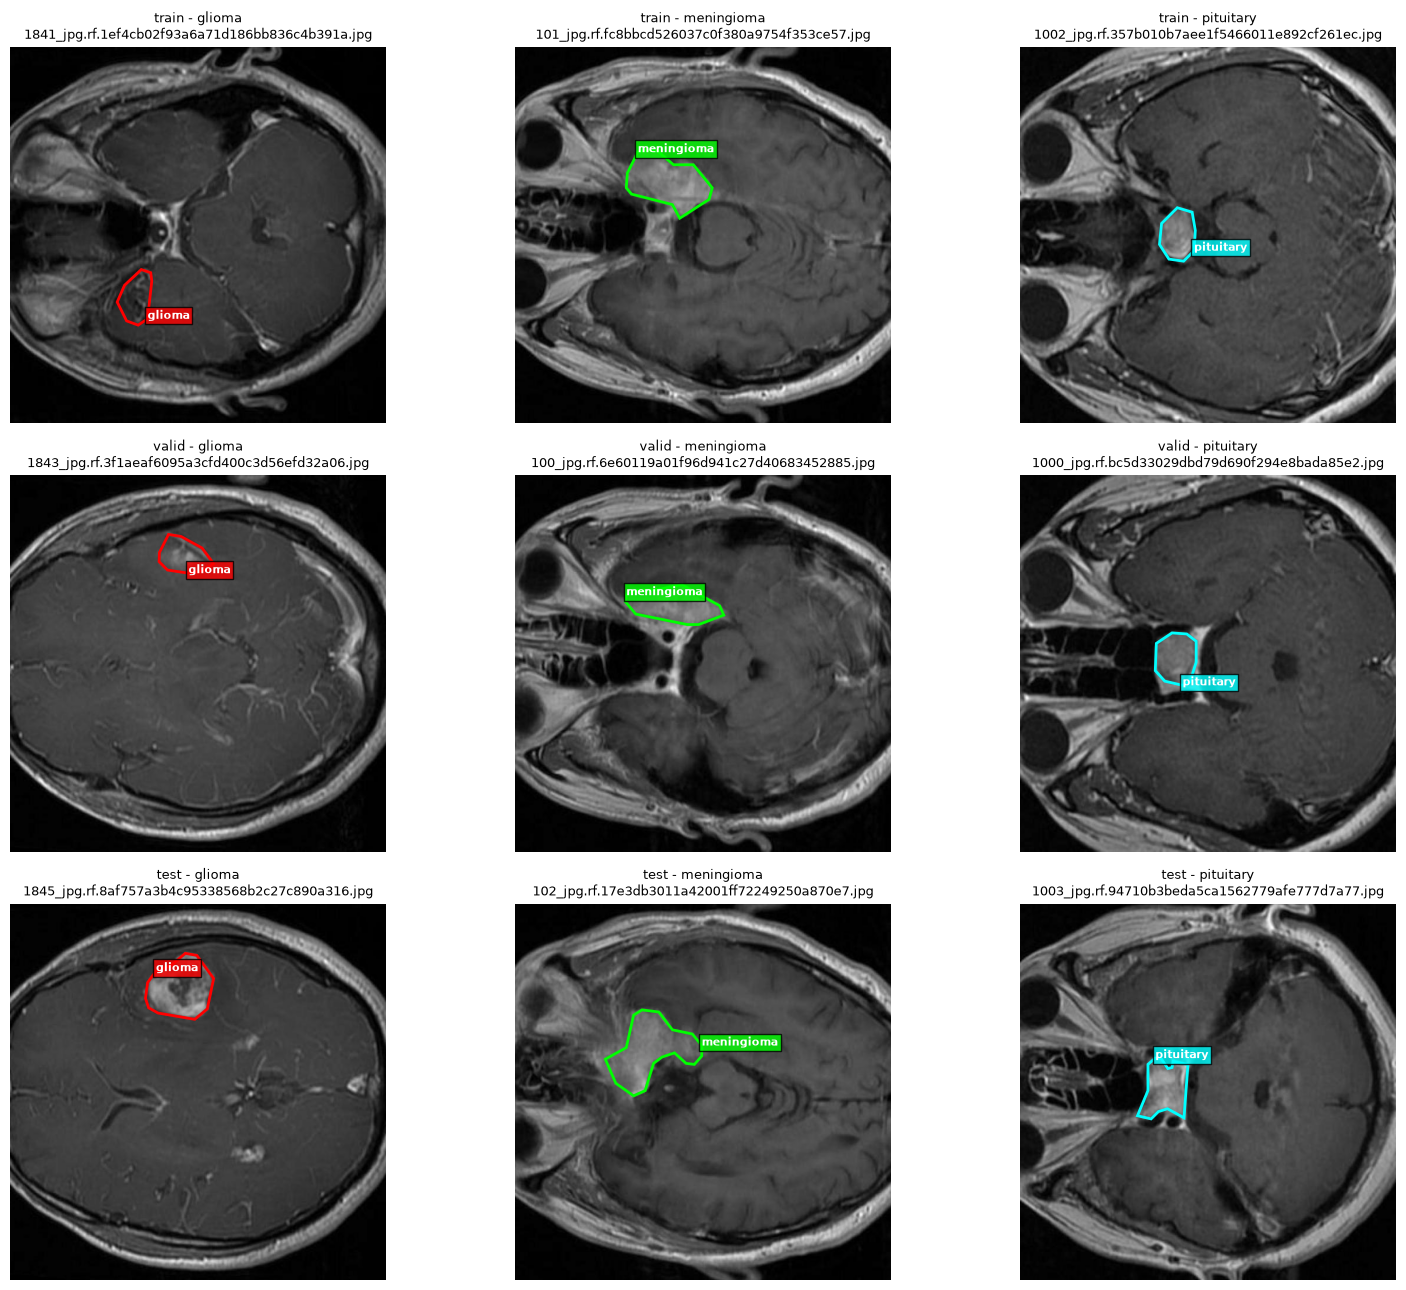

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image

# Les colonnes de la grille correspondent aux identifiants de classe 0, 1 et 2.
class_names = ["glioma", "meningioma", "pituitary"]
class_colors = ["red", "lime", "cyan"]
splits = ["train", "valid", "test"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Créer une grille : une ligne par dossier et une colonne par classe.
fig, axes = plt.subplots(nrows=len(splits), ncols=len(class_names), figsize=(16, 13))

for row, split in enumerate(splits):
    images_dir = dataset_dir / split / "images"
    labels_dir = dataset_dir / split / "labels"

    # Trier les images pour que le choix soit reproductible.
    image_paths = [
        image_path
        for image_path in sorted(images_dir.iterdir())
        if image_path.is_file() and image_path.suffix.lower() in image_extensions
    ]
    selected_images = set()

    # Chercher une image différente pour chacune des trois classes.
    for class_id, ax in enumerate(axes[row]):
        selected_image = None

        for image_path in image_paths:
            if image_path.stem in selected_images:
                continue

            label_path = labels_dir / f"{image_path.stem}.txt"
            if not label_path.is_file():
                continue

            # Lire le premier nombre de chaque ligne, qui indique la classe YOLO.
            with label_path.open("r") as label_file:
                image_classes = {
                    int(values[0])
                    for line in label_file
                    if len(values := line.split()) >= 7
                }

            if class_id in image_classes:
                selected_image = image_path
                selected_images.add(image_path.stem)
                break

        # Signaler dans la grille si cette classe n'a pas d'image annotée.
        if selected_image is None:
            ax.set_title(f"{split} - classe {class_names[class_id]} absente")
            ax.axis("off")
            continue

        # Charger l'image puis la dessiner dans le panneau correspondant.
        label_path = labels_dir / f"{selected_image.stem}.txt"
        image = Image.open(selected_image).convert("RGB")
        width, height = image.size
        ax.imshow(image)

        # Lire les polygones YOLO et convertir leurs coordonnées normalisées en pixels.
        with label_path.open("r") as label_file:
            for line in label_file:
                values = line.split()
                if len(values) < 7:
                    continue

                annotation_class = int(values[0])
                coordinates = [float(value) for value in values[1:]]
                points = [
                    (coordinates[i] * width, coordinates[i + 1] * height)
                    for i in range(0, len(coordinates) - 1, 2)
                ]

                # Tracer le contour et afficher le nom de la classe.
                color = class_colors[annotation_class % len(class_colors)]
                ax.add_patch(
                    Polygon(points, closed=True, fill=False, edgecolor=color, linewidth=2)
                )
                ax.text(
                    points[0][0], points[0][1], class_names[annotation_class],
                    color="white", fontsize=8, weight="bold",
                    bbox={"facecolor": color, "alpha": 0.8, "pad": 2},
                )

        ax.set_title(f"{split} - {class_names[class_id]}\n{selected_image.name}", fontsize=9)
        ax.axis("off")

# Ajuster les espacements et afficher les neuf panneaux.
fig.tight_layout()
plt.show()

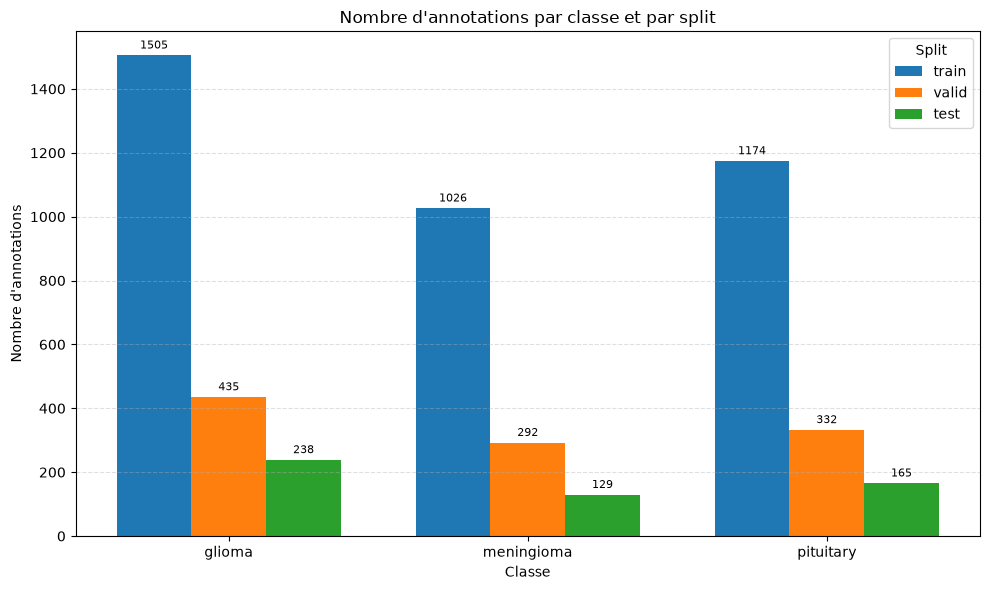

In [9]:
import matplotlib.pyplot as plt

# Les identifiants YOLO 0, 1 et 2 correspondent à ces classes.
class_names = ["glioma", "meningioma", "pituitary"]
splits = ["train", "valid", "test"]

# Initialiser à zéro le nombre d'annotations de chaque classe pour chaque split.
annotation_counts = {
    split: [0] * len(class_names)
    for split in splits
}

# Parcourir les fichiers texte : chaque ligne valide représente une annotation.
for split in splits:
    labels_dir = dataset_dir / split / "labels"

    for label_path in labels_dir.glob("*.txt"):
        with label_path.open("r") as label_file:
            for line in label_file:
                values = line.split()
                if not values:
                    continue

                # Le premier champ de chaque ligne est l'identifiant de classe.
                try:
                    class_id = int(values[0])
                except ValueError:
                    continue

                if 0 <= class_id < len(class_names):
                    annotation_counts[split][class_id] += 1

# Créer des barres côte à côte pour comparer les splits dans chaque classe.
positions = list(range(len(class_names)))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(10, 6))

for split_index, split in enumerate(splits):
    offsets = [
        position + (split_index - (len(splits) - 1) / 2) * bar_width
        for position in positions
    ]
    bars = ax.bar(offsets, annotation_counts[split], bar_width, label=split)
    ax.bar_label(bars, padding=3, fontsize=8)

# Ajouter les noms des classes, les axes, le titre et la légende.
ax.set_xticks(positions)
ax.set_xticklabels(class_names)
ax.set_ylabel("Nombre d'annotations")
ax.set_xlabel("Classe")
ax.set_title("Nombre d'annotations par classe et par split")
ax.legend(title="Split")
ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()

In [1]:
# PREPARATION COMMUNE DES DEMONSTRATIONS ET DES EXPORTS
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter

# Reutiliser les noms et le chemin du dataset declares dans les cellules precedentes.
dataset_dir = Path("dataset")

In [4]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon
from PIL import Image, ImageEnhance

# --- À ADAPTER : chemins du dataset (format YOLO standard) ---
dataset_dir = Path("dataset")
train_images_dir = dataset_dir / "train" / "images"
train_labels_dir = dataset_dir / "train" / "labels"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def read_yolo_polygons(label_path):
    """Lit un fichier YOLO segmentation.
    Chaque ligne : class_id x1 y1 x2 y2 ... (coordonnées normalisées 0-1).
    Retourne une liste de (class_id, array de forme (N, 2))."""
    polygons = []
    label_path = Path(label_path)
    if not label_path.exists():
        return polygons
    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 7:  # au moins classe + 3 points
            continue
        class_id = int(float(parts[0]))
        coords = np.array(parts[1:], dtype=float).reshape(-1, 2)
        polygons.append((class_id, coords))
    return polygons


def render_image_with_labels(ax, image, polygons, title=""):
    """Affiche l'image et superpose les polygones (dénormalisés)."""
    width, height = image.size
    ax.imshow(image)
    colors = plt.cm.tab10.colors
    for class_id, coords in polygons:
        pts = coords * np.array([width, height])
        color = colors[class_id % len(colors)]
        ax.add_patch(
            Polygon(pts, closed=True, fill=True,
                    facecolor=color, edgecolor=color,
                    alpha=0.35, linewidth=1.5)
        )
        ax.add_patch(
            Polygon(pts, closed=True, fill=False,
                    edgecolor=color, linewidth=1.5)
        )
    ax.set_title(title, fontsize=10)
    ax.axis("off")


# --- Sélection de six images train (qui ont un fichier label) ---
all_train_images = sorted(
    p for p in train_images_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTS
    and (train_labels_dir / f"{p.stem}.txt").exists()
)
random.seed(42)  # reproductible
six_train_images = random.sample(all_train_images, 6)
print(f"{len(all_train_images)} images trouvées, 6 sélectionnées.")

3710 images trouvées, 6 sélectionnées.


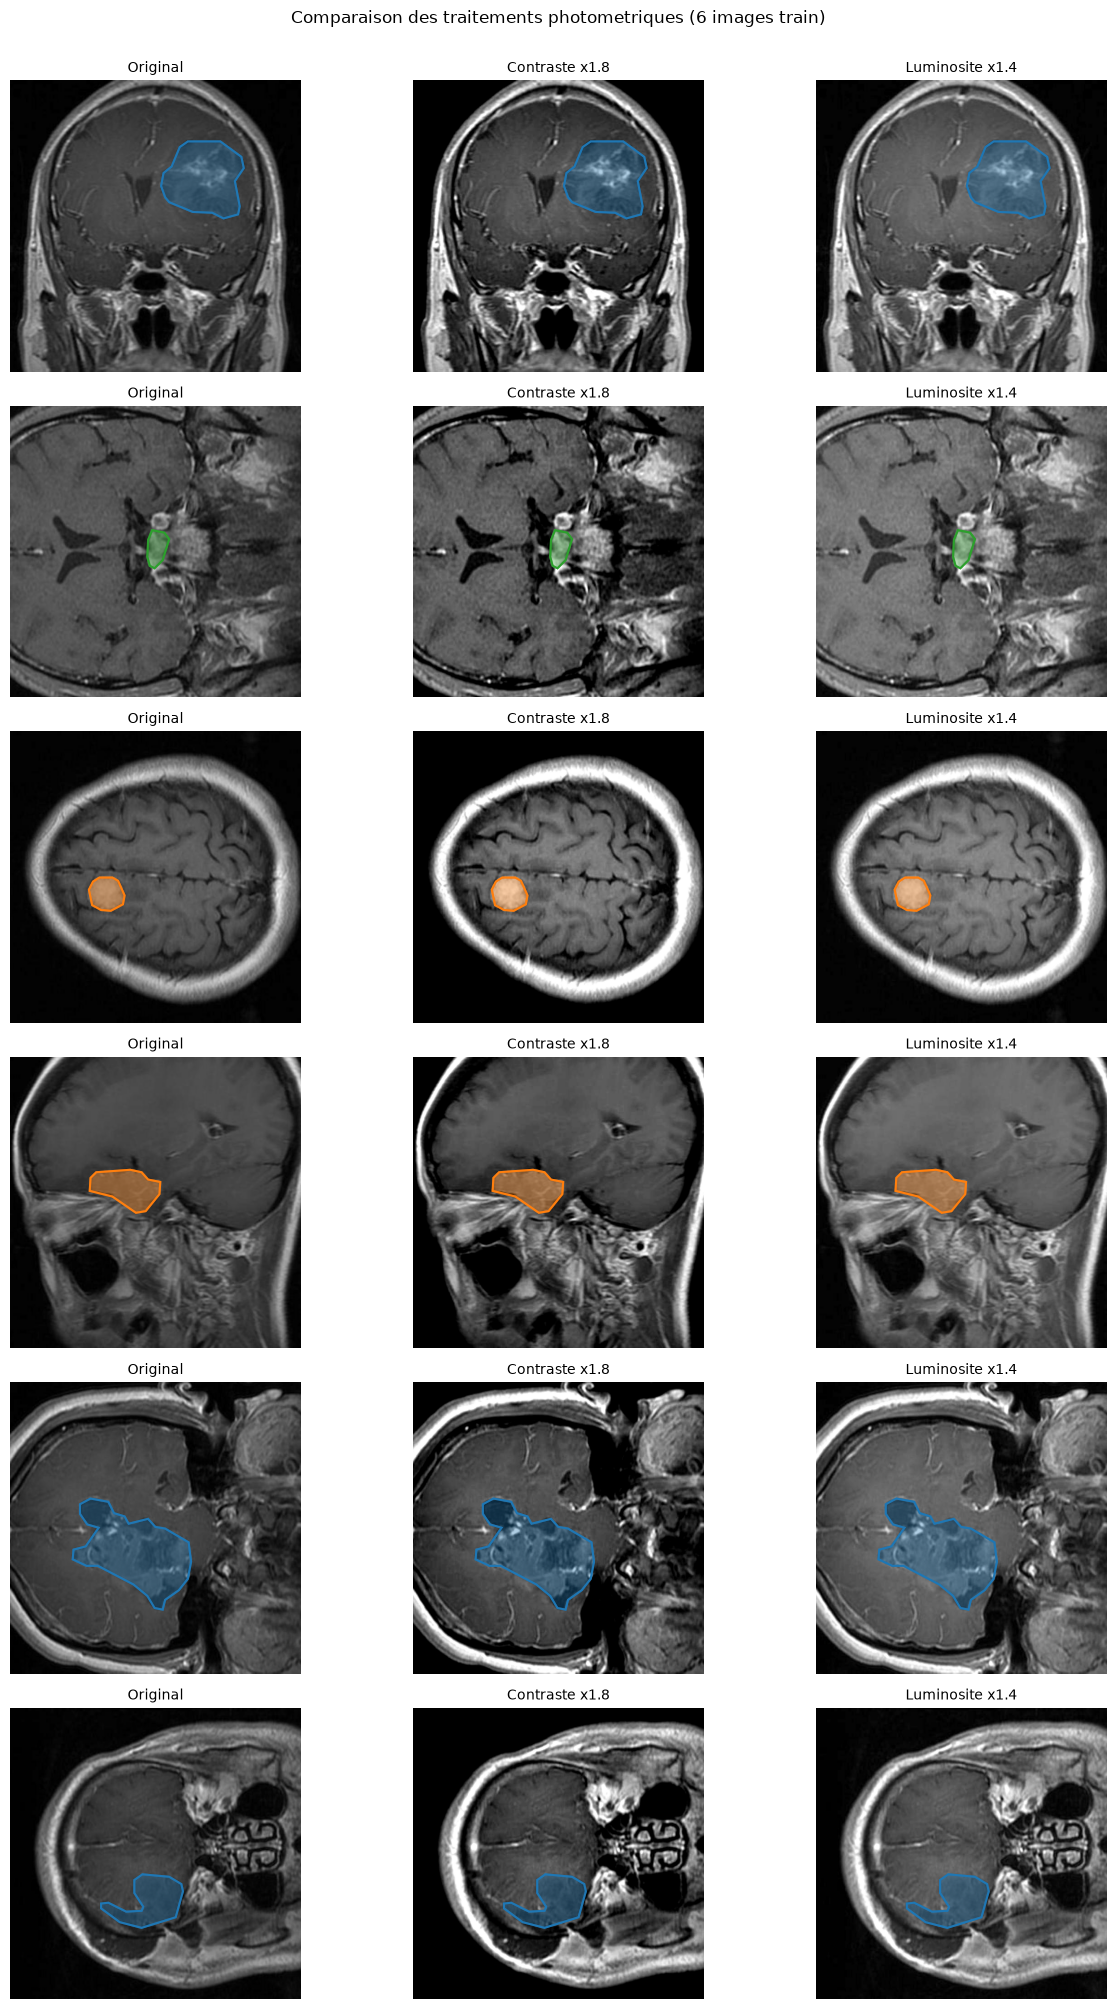

Interpretation : le contraste renforce l'ecart entre zones sombres et claires; la luminosite augmente globalement les intensites. Les deux reglages sont volontairement moderes : des valeurs trop fortes peuvent saturer les details. Les annotations restent identiques, car aucun pixel n'est deplace.


In [5]:
# DEMONSTRATION : ORIGINAL VS CONTRASTE VS LUMINOSITE SUR SIX IMAGES TRAIN
# Ces modifications photometriques ne changent pas la position des polygones.
contrast_factor = 1.8
brightness_factor = 1.4
fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(13, 20))

for row, image_path in enumerate(six_train_images):
    original = Image.open(image_path).convert("RGB")
    polygons = read_yolo_polygons(train_labels_dir / f"{image_path.stem}.txt")
    contrast_image = ImageEnhance.Contrast(original).enhance(contrast_factor)
    brighter_image = ImageEnhance.Brightness(original).enhance(brightness_factor)

    render_image_with_labels(axes[row, 0], original, polygons, "Original")
    render_image_with_labels(
        axes[row, 1], contrast_image, polygons,
        f"Contraste x{contrast_factor}",
    )
    render_image_with_labels(
        axes[row, 2], brighter_image, polygons,
        f"Luminosite x{brightness_factor}",
    )
    axes[row, 0].set_ylabel(image_path.stem[:18], fontsize=8)

fig.suptitle("Comparaison des traitements photometriques (6 images train)", y=1.002)
fig.tight_layout()
plt.show()
print(
    "Interpretation : le contraste renforce l'ecart entre zones sombres et claires; "
    "la luminosite augmente globalement les intensites. Les deux reglages sont volontairement "
    "moderes : des valeurs trop fortes peuvent saturer les details. Les annotations restent "
    "identiques, car aucun pixel n'est deplace."
)

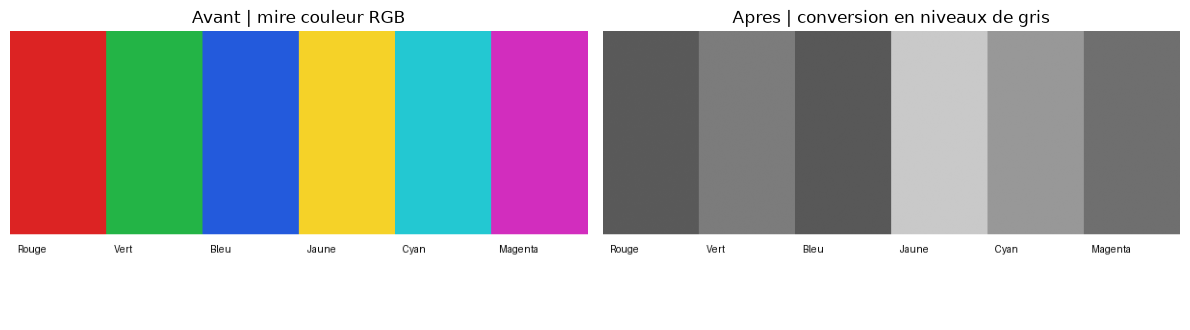

Interpretation : la conversion retire la teinte et la saturation, mais conserve une intensite lumineuse derivee des canaux rouge, vert et bleu. Ici, les bandes colorees deviennent des tons de gris differents; ce bloc est une demonstration, pas une transformation appliquee au dataset.


In [23]:
# DEMONSTRATION SEPAREE : CONVERSION D'UNE IMAGE COULEUR EN NIVEAUX DE GRIS
# Le dataset d'IRM est monochrome; cette mire couleur illustre mieux la perte de teinte.
color_demo = Image.new("RGB", (600, 300), "white")
draw = ImageDraw.Draw(color_demo)
color_bands = [
    ("Rouge", (220, 35, 35)),
    ("Vert", (35, 180, 70)),
    ("Bleu", (35, 90, 220)),
    ("Jaune", (245, 210, 40)),
    ("Cyan", (35, 200, 210)),
    ("Magenta", (210, 45, 190)),
]
band_width = color_demo.width // len(color_bands)
for index, (color_name, rgb_color) in enumerate(color_bands):
    left = index * band_width
    right = color_demo.width if index == len(color_bands) - 1 else (index + 1) * band_width
    draw.rectangle((left, 0, right, 210), fill=rgb_color)
    draw.text((left + 8, 220), color_name, fill="black")

gray_demo = color_demo.convert("L")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
axes[0].imshow(color_demo)
axes[0].set_title("Avant | mire couleur RGB")
axes[0].axis("off")
axes[1].imshow(gray_demo, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Apres | conversion en niveaux de gris")
axes[1].axis("off")
fig.tight_layout()
plt.show()
print(
    "Interpretation : la conversion retire la teinte et la saturation, mais conserve "
    "une intensite lumineuse derivee des canaux rouge, vert et bleu. Ici, les bandes "
    "colorees deviennent des tons de gris differents; ce bloc est une demonstration, "
    "pas une transformation appliquee au dataset."
)

In [6]:
# À ADAPTER : noms de vos classes, dans l'ordre de votre data.yaml
class_names = ["tumeur"]  # ex. ["glioma", "meningioma", "pituitary"]


def class_label(class_id):
    """Nom de classe, avec repli sur l'identifiant si non défini."""
    if 0 <= class_id < len(class_names):
        return class_names[class_id]
    return f"classe {class_id}"


def transform_polygons(polygons, operation):
    """Applique à des polygones normalisés (x, y) la même transformation
    que celle appliquée à l'image par PIL.transpose."""
    transformed = []
    for class_id, coords in polygons:
        x, y = coords[:, 0], coords[:, 1]
        if operation == "rotation_90":        # PIL ROTATE_90 = 90° anti-horaire
            new_coords = np.stack([y, 1 - x], axis=1)
        elif operation == "flip_horizontal":  # FLIP_LEFT_RIGHT
            new_coords = np.stack([1 - x, y], axis=1)
        else:
            raise ValueError(f"Opération inconnue : {operation}")
        transformed.append((class_id, new_coords))
    return transformed

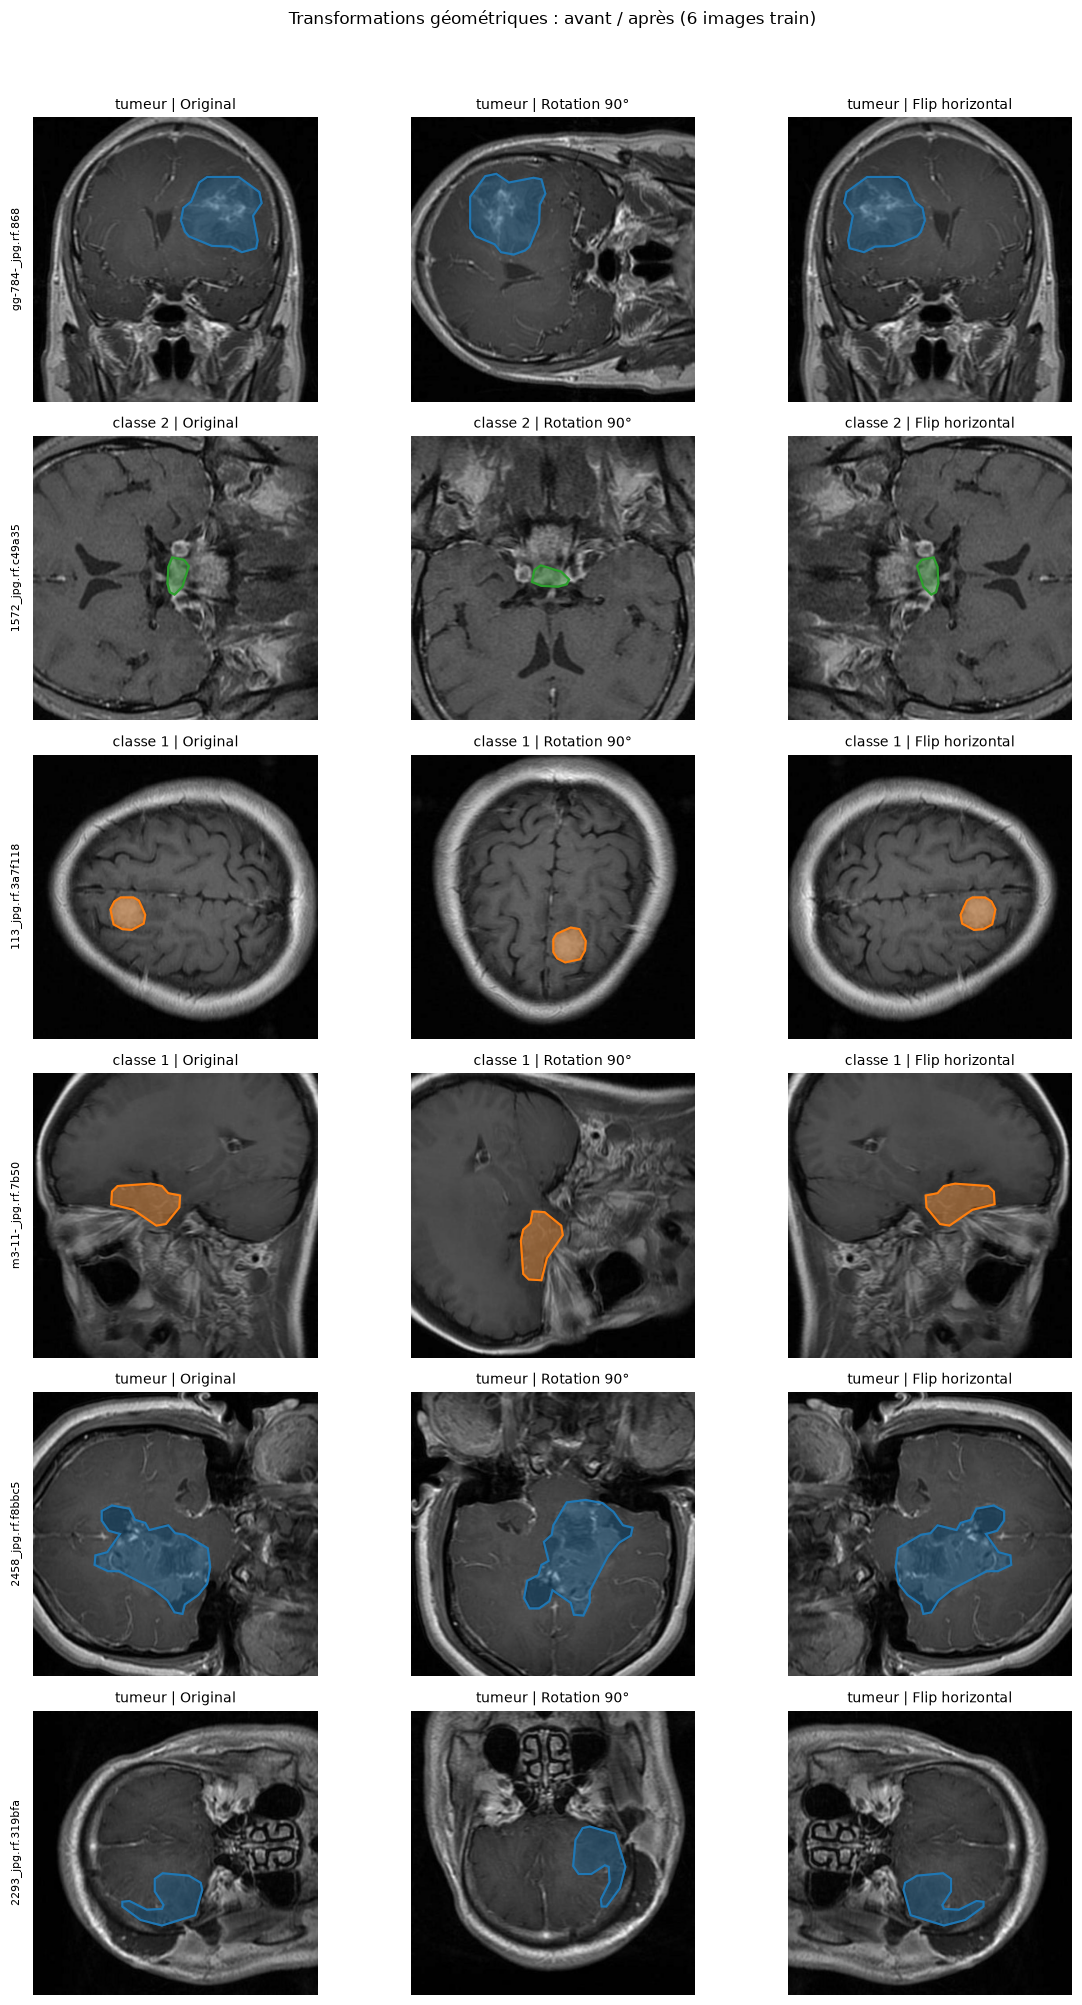

Interprétation : la rotation et le flip créent des vues différentes tout en gardant la tumeur étiquetée au bon endroit. Les polygones doivent subir exactement la même transformation que l'image ; le code d'augmentation ci-dessous le fait.


In [8]:
# DEMONSTRATION 2 : ROTATIONS ET FLIPS, AVEC MISE A JOUR DES POLYGONES
geometric_variants = [
    ("Original", None, None),
    ("Rotation 90°", Image.Transpose.ROTATE_90, "rotation_90"),
    ("Flip horizontal", Image.Transpose.FLIP_LEFT_RIGHT, "flip_horizontal"),
]
fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(12, 20))

for row, image_path in enumerate(six_train_images):
    with Image.open(image_path) as img:
        original = img.convert("RGB")
    polygons = read_yolo_polygons(train_labels_dir / f"{image_path.stem}.txt")
    name = class_label(polygons[0][0]) if polygons else "sans label"

    for column, (variant_name, pil_operation, point_operation) in enumerate(geometric_variants):
        if pil_operation is None:
            changed_image = original.copy()
            changed_polygons = polygons
        else:
            changed_image = original.transpose(pil_operation)
            changed_polygons = transform_polygons(polygons, point_operation)
        render_image_with_labels(
            axes[row, column], changed_image, changed_polygons,
            f"{name} | {variant_name}",
        )

    # texte en coordonnées d'axe, car render_image_with_labels fait axis("off")
    axes[row, 0].text(
        -0.04, 0.5, image_path.stem[:18],
        transform=axes[row, 0].transAxes,
        rotation=90, va="center", ha="right", fontsize=8,
    )

fig.suptitle("Transformations géométriques : avant / après (6 images train)", y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()
print(
    "Interprétation : la rotation et le flip créent des vues différentes tout en gardant "
    "la tumeur étiquetée au bon endroit. Les polygones doivent subir exactement la même "
    "transformation que l'image ; le code d'augmentation ci-dessous le fait."
)

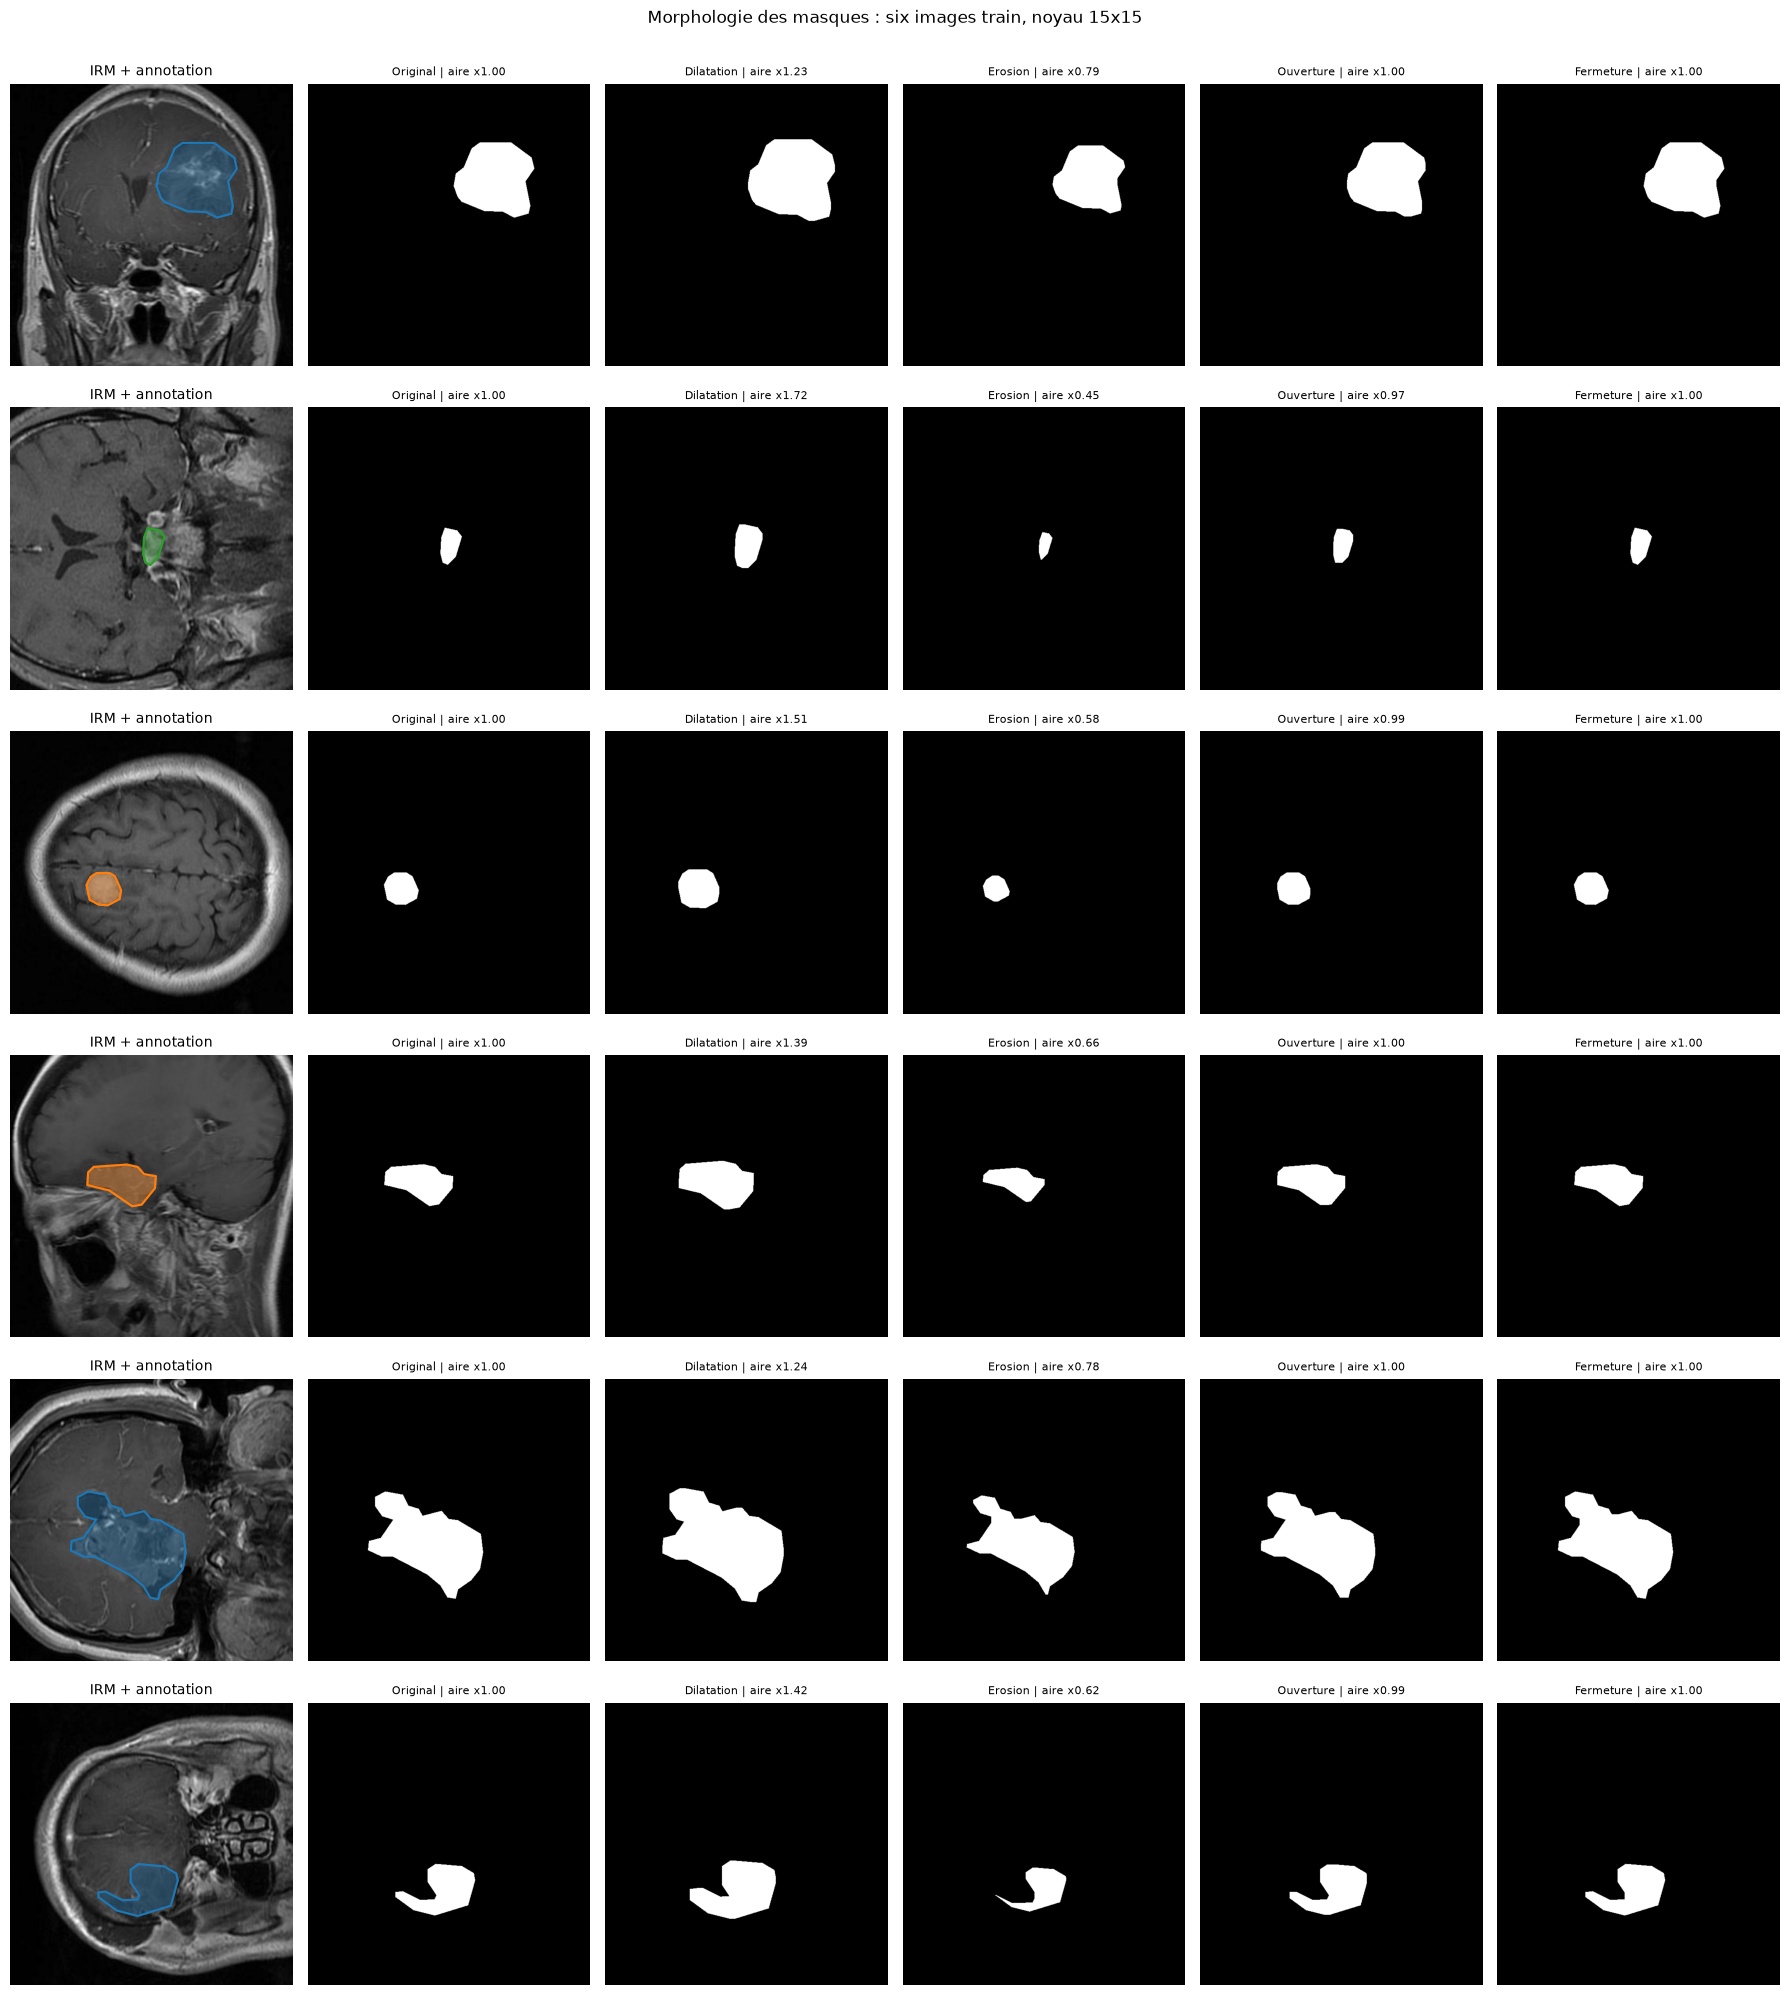

Rapport aire du masque transforme / aire originale :
gg-784-_jpg.rf.8686baf223c0b1f2aca8bc6d95ad1652.jpg {'original': 1.0, 'dilatation': 1.23, 'erosion': 0.79, 'ouverture': 1.0, 'fermeture': 1.0}
1572_jpg.rf.c49a3526dec92f1a1420895c2924b5f4.jpg {'original': 1.0, 'dilatation': 1.72, 'erosion': 0.45, 'ouverture': 0.97, 'fermeture': 1.0}
113_jpg.rf.3a7f1181d6f553ae9fe93ca21c334f18.jpg {'original': 1.0, 'dilatation': 1.51, 'erosion': 0.58, 'ouverture': 0.99, 'fermeture': 1.0}
m3-11-_jpg.rf.7b50ff6189d029461e76a11d59dd0be4.jpg {'original': 1.0, 'dilatation': 1.39, 'erosion': 0.66, 'ouverture': 1.0, 'fermeture': 1.0}
2458_jpg.rf.f8bbc55468bb3633bdcb6c714bf5631f.jpg {'original': 1.0, 'dilatation': 1.24, 'erosion': 0.78, 'ouverture': 1.0, 'fermeture': 1.0}
2293_jpg.rf.319bfa16f8e2b9b71e38c16c71d19729.jpg {'original': 1.0, 'dilatation': 1.42, 'erosion': 0.62, 'ouverture': 0.99, 'fermeture': 1.0}
Interpretation : la dilatation elargit la region marquee; l'erosion la retrecit. L'ouverture supprim

In [9]:
# DEMONSTRATION 3 : OPERATIONS MORPHOLOGIQUES SUR LES MASQUES
# Les operations s'appliquent au masque de segmentation, pas directement a l'image IRM.
def polygons_to_binary_mask(image_size, polygons):
    mask = Image.new("L", image_size, 0)
    draw = ImageDraw.Draw(mask)
    width, height = image_size
    for _, points in polygons:
        pixel_points = [
            (round(x * (width - 1)), round(y * (height - 1)))
            for x, y in points
        ]
        draw.polygon(pixel_points, fill=255)
    return mask


def apply_morphology(mask, operation, kernel_size=15):
    """Appliquer une operation morphologique avec un noyau carre impair."""
    if operation == "dilatation":
        return mask.filter(ImageFilter.MaxFilter(kernel_size))
    if operation == "erosion":
        return mask.filter(ImageFilter.MinFilter(kernel_size))
    if operation == "ouverture":
        eroded = mask.filter(ImageFilter.MinFilter(kernel_size))
        return eroded.filter(ImageFilter.MaxFilter(kernel_size))
    if operation == "fermeture":
        dilated = mask.filter(ImageFilter.MaxFilter(kernel_size))
        return dilated.filter(ImageFilter.MinFilter(kernel_size))
    return mask.copy()


morphology_operations = ["original", "dilatation", "erosion", "ouverture", "fermeture"]
morphology_area_changes = []
fig, axes = plt.subplots(nrows=6, ncols=6, figsize=(18, 20))

for row, image_path in enumerate(six_train_images):
    image = Image.open(image_path).convert("RGB")
    polygons = read_yolo_polygons(train_labels_dir / f"{image_path.stem}.txt")
    mask = polygons_to_binary_mask(image.size, polygons)
    mask_variants = [
        apply_morphology(mask, operation, kernel_size=15)
        for operation in morphology_operations
    ]
    original_area = max(np.asarray(mask, dtype=np.uint8).astype(bool).sum(), 1)
    area_ratios = {
        operation: float(np.asarray(variant, dtype=np.uint8).astype(bool).sum() / original_area)
        for operation, variant in zip(morphology_operations, mask_variants)
    }
    morphology_area_changes.append(area_ratios)

    # Premiere colonne : IRM et annotation d'origine; suivantes : masques transformes.
    render_image_with_labels(axes[row, 0], image, polygons, "IRM + annotation")
    for column, (operation, mask_variant) in enumerate(
        zip(morphology_operations, mask_variants), start=1
    ):
        axes[row, column].imshow(mask_variant, cmap="gray", vmin=0, vmax=255)
        axes[row, column].set_title(f"{operation.capitalize()} | aire x{area_ratios[operation]:.2f}", fontsize=8)
        axes[row, column].axis("off")
    axes[row, 0].set_ylabel(image_path.stem[:18], fontsize=8)

fig.suptitle("Morphologie des masques : six images train, noyau 15x15", y=1.002)
fig.tight_layout()
plt.show()
print("Rapport aire du masque transforme / aire originale :")
for image_path, ratios in zip(six_train_images, morphology_area_changes):
    print(image_path.name, {name: round(ratios[name], 2) for name in morphology_operations})
print(
    "Interpretation : la dilatation elargit la region marquee; l'erosion la retrecit. "
    "L'ouverture supprime de petits elements saillants, la fermeture comble de petits trous. "
    "Un noyau trop grand peut effacer une petite tumeur ou deformer sa limite; conserver "
    "le masque source et valider le noyau visuellement."
)

train: 3710 images, 3705 annotations COCO, masques dans outputs/preprocessing/conversion/train/masks
valid: 1059 images, 1059 annotations COCO, masques dans outputs/preprocessing/conversion/valid/masks
test: 532 images, 532 annotations COCO, masques dans outputs/preprocessing/conversion/test/masks


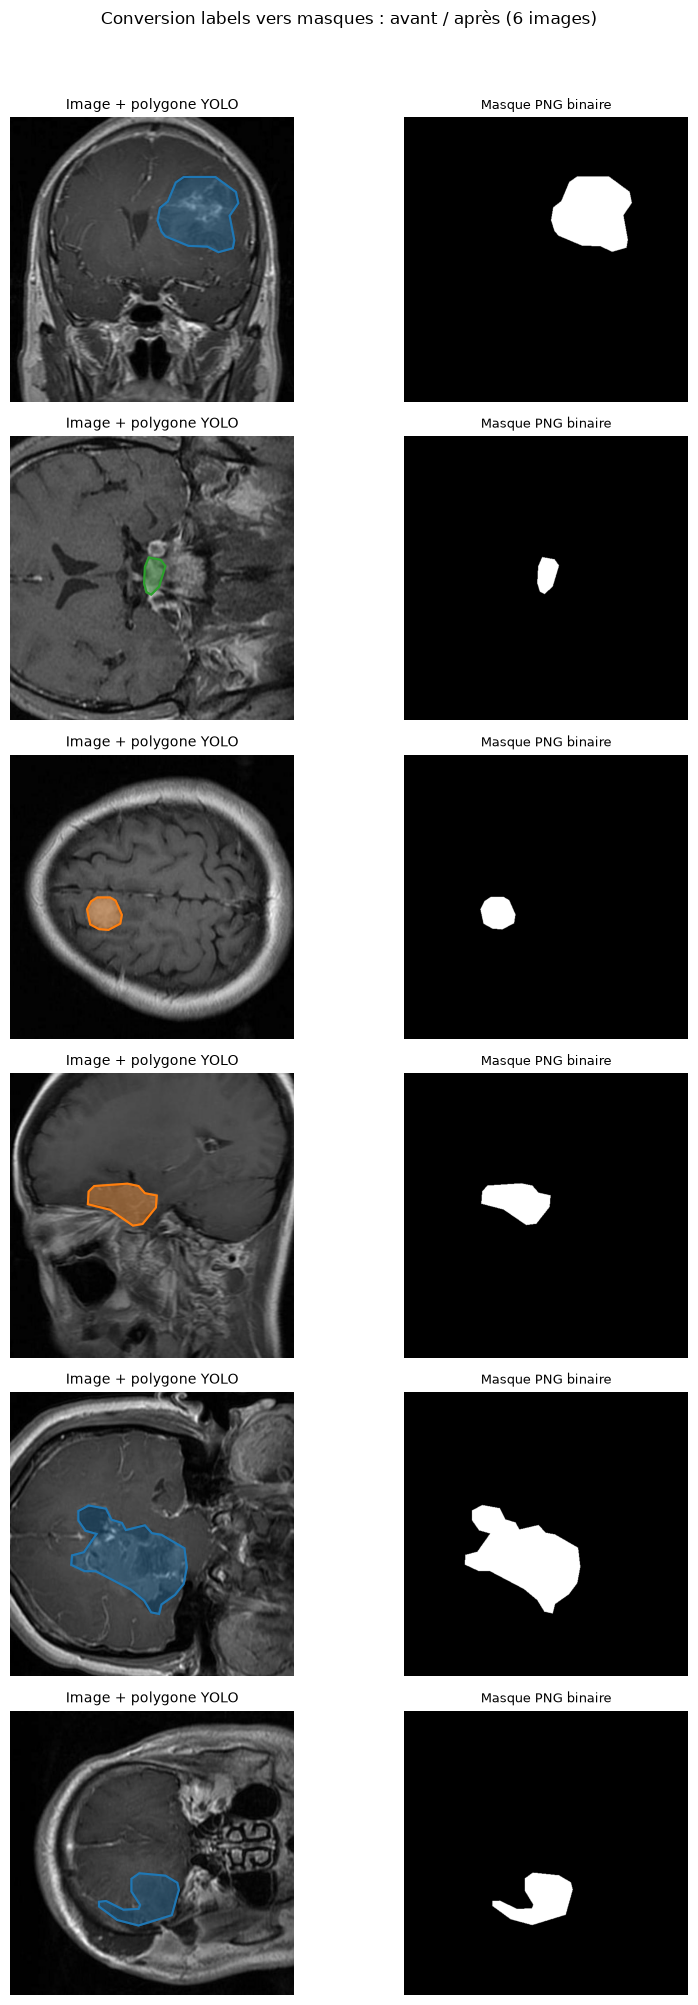

Interprétation : le JSON COCO conserve une annotation par polygone, sa classe, sa boîte et sa surface ; le PNG binaire regroupe les régions tumorales en un masque fond/tumeur. Le masque est adapté à une segmentation binaire, COCO garde les instances.
Fichiers JSON COCO : {'train': PosixPath('outputs/preprocessing/conversion/train/annotations_coco.json'), 'valid': PosixPath('outputs/preprocessing/conversion/valid/annotations_coco.json'), 'test': PosixPath('outputs/preprocessing/conversion/test/annotations_coco.json')}
Masques PNG : outputs/preprocessing/conversion


In [11]:
# CONVERSION DES LABELS YOLO EN MASQUES PNG ET EN JSON COCO
# Les sources restent intactes; un JSON et un masque binaire sont crees pour chaque split.
import json

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

# Définition manquante (alias de IMAGE_EXTS si déjà défini)
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

conversion_root = Path("outputs/preprocessing/conversion")
conversion_root.mkdir(parents=True, exist_ok=True)


def polygon_pixel_coordinates(points, width, height):
    return [
        (
            float(min(max(x, 0.0), 1.0) * (width - 1)),
            float(min(max(y, 0.0), 1.0) * (height - 1)),
        )
        for x, y in points
    ]


coco_exports = {}
for split in ("train", "valid", "test"):
    images_dir = dataset_dir / split / "images"
    labels_dir = dataset_dir / split / "labels"
    split_output = conversion_root / split
    masks_dir = split_output / "masks"
    masks_dir.mkdir(parents=True, exist_ok=True)

    coco_document = {
        "info": {"description": f"Tumor segmentation {split}", "version": "1.0"},
        "licenses": [],
        "images": [],
        "annotations": [],
        "categories": [
            {"id": class_id + 1, "name": name, "supercategory": "tumor"}
            for class_id, name in enumerate(class_names)
        ],
    }

    image_id = 0
    annotation_id = 1
    for image_path in sorted(images_dir.iterdir()):
        if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
            continue
        image_id += 1
        with Image.open(image_path) as img:   # seule la taille est nécessaire
            width, height = img.size
        polygons = read_yolo_polygons(labels_dir / f"{image_path.stem}.txt")
        union_mask = Image.new("L", (width, height), 0)
        union_draw = ImageDraw.Draw(union_mask)

        coco_document["images"].append(
            {"id": image_id, "file_name": image_path.name,
             "width": width, "height": height}
        )

        for class_id, normalized_points in polygons:
            points = polygon_pixel_coordinates(normalized_points, width, height)

            # Masque de cette instance (sert à la bbox et à l'aire)
            instance_mask = Image.new("L", (width, height), 0)
            ImageDraw.Draw(instance_mask).polygon(points, fill=255)
            union_draw.polygon(points, fill=255)

            bbox = instance_mask.getbbox()
            if bbox is None:
                continue
            left, top, right, bottom = bbox
            pixel_segmentation = [c for point in points for c in point]
            coco_document["annotations"].append(
                {
                    "id": annotation_id,
                    "image_id": image_id,
                    "category_id": int(class_id) + 1,
                    "segmentation": [pixel_segmentation],
                    "area": int((np.asarray(instance_mask) > 0).sum()),
                    "bbox": [left, top, right - left, bottom - top],
                    "iscrowd": 0,
                }
            )
            annotation_id += 1

        # Chaque PNG est un masque binaire d'union (0=fond, 255=tumeur).
        union_mask.save(masks_dir / f"{image_path.stem}_mask.png")

    json_path = split_output / "annotations_coco.json"
    json_path.write_text(json.dumps(coco_document, indent=2), encoding="utf-8")
    coco_exports[split] = json_path
    print(
        f"{split}: {len(coco_document['images'])} images, "
        f"{len(coco_document['annotations'])} annotations COCO, "
        f"masques dans {masks_dir}"
    )

# Afficher six conversions image + masque et superposer le contour d'origine.
fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(9, 20))
for row, image_path in enumerate(six_train_images):
    with Image.open(image_path) as img:
        image = img.convert("RGB")
    polygons = read_yolo_polygons(train_labels_dir / f"{image_path.stem}.txt")
    mask_path = conversion_root / "train" / "masks" / f"{image_path.stem}_mask.png"
    with Image.open(mask_path) as m:
        mask = m.convert("L")
    render_image_with_labels(axes[row, 0], image, polygons, "Image + polygone YOLO")
    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title("Masque PNG binaire", fontsize=9)
    axes[row, 1].axis("off")

fig.suptitle("Conversion labels vers masques : avant / après (6 images)", y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()
print(
    "Interprétation : le JSON COCO conserve une annotation par polygone, sa classe, "
    "sa boîte et sa surface ; le PNG binaire regroupe les régions tumorales en un masque "
    "fond/tumeur. Le masque est adapté à une segmentation binaire, COCO garde les instances."
)
print("Fichiers JSON COCO :", coco_exports)
print(f"Masques PNG : {conversion_root}")

In [25]:
# EXTRAIRE UN PETIT DATASET EQUILIBRE POUR ENTRAINER SUR UNE MACHINE LIMITEE
# Le dataset source n'est pas modifie; seuls des exemples train/valid/test sont copies.
from collections import Counter
from datetime import datetime
import random
import shutil
import yaml

small_dataset_root = Path("outputs/preprocessing") / f"small_balanced_{datetime.now():%Y%m%d_%H%M%S}"
small_dataset_root.mkdir(parents=True, exist_ok=False)

# Modifier ces limites pour creer un jeu encore plus petit ou plus grand.
SAMPLES_PER_CLASS = {
    "train": 100,
    "valid": 20,
    "test": 20,
}
random_seed = 42
random_generator = random.Random(random_seed)


def records_for_split(split_name):
    """Lister les images avec un label YOLO non vide et une seule classe."""
    split_images_dir = dataset_dir / split_name / "images"
    split_labels_dir = dataset_dir / split_name / "labels"
    records_by_class = {class_id: [] for class_id in range(len(class_names))}

    for image_path in sorted(split_images_dir.iterdir()):
        if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
            continue
        label_path = split_labels_dir / f"{image_path.stem}.txt"
        polygons = read_yolo_polygons(label_path)
        image_classes = {class_id for class_id, _ in polygons}
        if len(image_classes) == 1:
            class_id = next(iter(image_classes))
            records_by_class[class_id].append((image_path, label_path))
    return records_by_class


small_dataset_counts = {}
for split_name, requested_per_class in SAMPLES_PER_CLASS.items():
    source_by_class = records_for_split(split_name)
    output_images_dir = small_dataset_root / split_name / "images"
    output_labels_dir = small_dataset_root / split_name / "labels"
    output_images_dir.mkdir(parents=True, exist_ok=True)
    output_labels_dir.mkdir(parents=True, exist_ok=True)

    # Pour garantir l'equilibre, limiter toutes les classes au minimum disponible.
    available_per_class = min(len(source_by_class[class_id]) for class_id in range(len(class_names)))
    selected_per_class = min(requested_per_class, available_per_class)
    if selected_per_class < requested_per_class:
        print(
            f"Attention: {split_name} ne permet que {selected_per_class} images par classe "
            f"(limite demandee: {requested_per_class})."
        )

    split_counts = Counter()
    for class_id in range(len(class_names)):
        candidates = source_by_class[class_id]
        selected_records = random_generator.sample(candidates, selected_per_class)
        for image_path, label_path in selected_records:
            shutil.copy2(image_path, output_images_dir / image_path.name)
            shutil.copy2(label_path, output_labels_dir / label_path.name)
            split_counts[class_id] += 1

    small_dataset_counts[split_name] = split_counts
    print(
        f"{split_name}: "
        + ", ".join(
            f"{class_names[class_id]}={split_counts[class_id]}"
            for class_id in range(len(class_names))
        )
    )

# Ecrire un YAML propre au sous-dataset, avec chemins absolus non ambigus.
small_data_yaml = small_dataset_root / "data.yaml"
yaml_config = {
    "path": str(small_dataset_root.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names,
}
small_data_yaml.write_text(yaml.safe_dump(yaml_config, sort_keys=False), encoding="utf-8")

# Controle rapide: chaque image exportee a exactement un fichier label correspondant.
for split_name in SAMPLES_PER_CLASS:
    images_dir = small_dataset_root / split_name / "images"
    labels_dir = small_dataset_root / split_name / "labels"
    image_stems = {path.stem for path in images_dir.iterdir() if path.is_file()}
    label_stems = {path.stem for path in labels_dir.glob("*.txt")}
    assert image_stems == label_stems, f"Paires image-label incorrectes dans {split_name}"
    assert len(set(small_dataset_counts[split_name].values())) == 1

print(f"Petit dataset cree dans : {small_dataset_root}")
print(f"Configuration YOLO : {small_data_yaml}")
print("Utilise ce chemin data=... pour entrainer le modele; les dossiers dataset/ d'origine restent intacts.")

train: glioma=100, meningioma=100, pituitary=100
valid: glioma=20, meningioma=20, pituitary=20
test: glioma=20, meningioma=20, pituitary=20
Petit dataset cree dans : outputs/preprocessing/small_balanced_20261006_104757
Configuration YOLO : outputs/preprocessing/small_balanced_20261006_104757/data.yaml
Utilise ce chemin data=... pour entrainer le modele; les dossiers dataset/ d'origine restent intacts.


Distribution des images par split et par classe :
Split     glioma         meningioma     pituitary      Total
train     100            100            100            300
valid     50             50             50             150
test      50             50             50             150
TOTAL: 600 images (200 par classe)


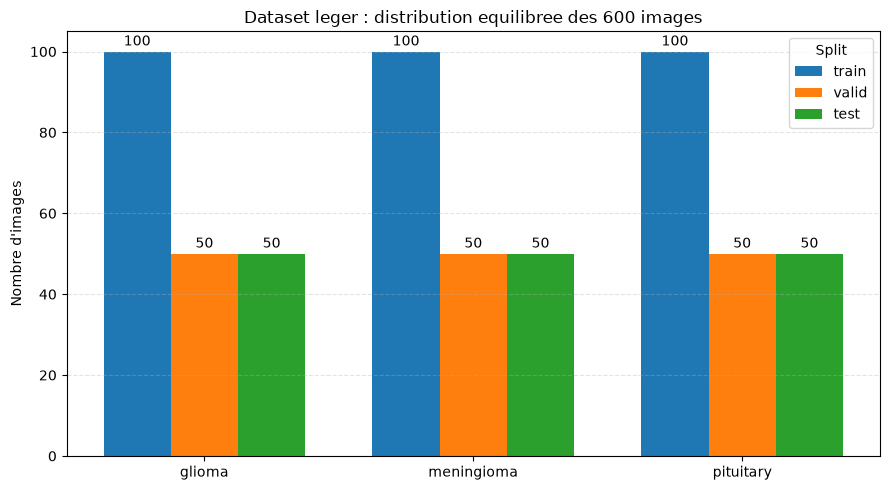

Dataset cree dans : /Users/ikram/Desktop/github-project/etude_de_cas__paris_cite_M2/small_dataset
Fichier de configuration YOLO : /Users/ikram/Desktop/github-project/etude_de_cas__paris_cite_M2/small_dataset/data.yaml
Pour l'entrainement YOLO : model.train(data=str(small_data_yaml), ...)


In [26]:
# EXTRAIRE UN DATASET EQUILIBRE DE 600 IMAGES POUR L'ENTRAINEMENT
from collections import Counter
import random
import shutil
import yaml

source_dataset = Path("dataset").resolve()
small_dataset = Path("small_dataset").resolve()

# Repartition equilibree : 300 train + 150 validation + 150 test = 600 images.
images_per_class = {
    "train": 100,
    "valid": 50,
    "test": 50,
}
random_seed = 42

# Ne pas ecraser un export precedent ou des fichiers qui existeraient deja.
if small_dataset.exists() and any(small_dataset.iterdir()):
    raise FileExistsError(
        f"{small_dataset} contient deja des fichiers. Renomme-le ou deplace son contenu avant de recreer l'export."
    )
small_dataset.mkdir(parents=True, exist_ok=True)

class_ids = range(len(class_names))
distribution = {}

for split, quota_per_class in images_per_class.items():
    source_images = source_dataset / split / "images"
    source_labels = source_dataset / split / "labels"
    output_images = small_dataset / split / "images"
    output_labels = small_dataset / split / "labels"
    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)

    # Regrouper les paires image-label selon leur classe unique.
    records_by_class = {class_id: [] for class_id in class_ids}
    for image_path in sorted(source_images.iterdir()):
        if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
            continue
        label_path = source_labels / f"{image_path.stem}.txt"
        polygons = read_yolo_polygons(label_path)
        present_classes = {class_id for class_id, _ in polygons}
        if len(present_classes) == 1:
            records_by_class[next(iter(present_classes))].append((image_path, label_path))

    # Verifier les quotas avant de copier quoi que ce soit pour ce split.
    insufficient = {
        class_names[class_id]: len(records_by_class[class_id])
        for class_id in class_ids
        if len(records_by_class[class_id]) < quota_per_class
    }
    if insufficient:
        raise ValueError(
            f"Pas assez d'images pour le quota {split} de {quota_per_class} par classe : {insufficient}"
        )

    split_counts = Counter()
    for class_id in class_ids:
        generator = random.Random(f"{random_seed}-{split}-{class_id}")
        selected_pairs = generator.sample(records_by_class[class_id], quota_per_class)
        for image_path, label_path in selected_pairs:
            shutil.copy2(image_path, output_images / image_path.name)
            shutil.copy2(label_path, output_labels / label_path.name)
            split_counts[class_id] += 1
    distribution[split] = split_counts

# Generer la configuration YOLO directement dans small_dataset/.
small_data_yaml = small_dataset / "data.yaml"
yaml_config = {
    "path": str(small_dataset),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names,
}
small_data_yaml.write_text(yaml.safe_dump(yaml_config, sort_keys=False), encoding="utf-8")

# Verifier le total, l'equilibre et l'appariement de toutes les images avec leurs labels.
total_images = 0
for split, quota_per_class in images_per_class.items():
    images_dir = small_dataset / split / "images"
    labels_dir = small_dataset / split / "labels"
    image_stems = {path.stem for path in images_dir.iterdir() if path.is_file()}
    label_stems = {path.stem for path in labels_dir.glob("*.txt")}
    assert image_stems == label_stems, f"Paires image-label incorrectes dans {split}"
    assert all(distribution[split][class_id] == quota_per_class for class_id in class_ids)
    total_images += len(image_stems)

assert total_images == 600, f"Le dataset contient {total_images} images au lieu de 600"
print("Distribution des images par split et par classe :")
print(f"{'Split':<10}" + "".join(f"{name:<15}" for name in class_names) + "Total")
for split in images_per_class:
    split_total = sum(distribution[split].values())
    print(
        f"{split:<10}"
        + "".join(f"{distribution[split][class_id]:<15}" for class_id in class_ids)
        + str(split_total)
    )
print(f"TOTAL: {total_images} images (200 par classe)")

# Afficher la distribution sous forme de barres groupees.
positions = np.arange(len(class_names))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(9, 5))
for split_index, split in enumerate(images_per_class):
    values = [distribution[split][class_id] for class_id in class_ids]
    offsets = positions + (split_index - 1) * bar_width
    bars = ax.bar(offsets, values, bar_width, label=split)
    ax.bar_label(bars, padding=2)
ax.set_xticks(positions)
ax.set_xticklabels(class_names)
ax.set_ylabel("Nombre d'images")
ax.set_title("Dataset leger : distribution equilibree des 600 images")
ax.legend(title="Split")
ax.grid(axis="y", linestyle="--", alpha=0.35)
fig.tight_layout()
plt.show()

print(f"Dataset cree dans : {small_dataset}")
print(f"Fichier de configuration YOLO : {small_data_yaml}")
print("Pour l'entrainement YOLO : model.train(data=str(small_data_yaml), ...)")